In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Circle
from skimage import measure

# %matplotlib widget


## Gravitační ekvipotenciály v systéme Zem - Mesiac

Ekvipotenciály sú plochy (krivky v 2D) na ktorých je potenciál konštantný. Sila je kolmá na ekvipotenciály.

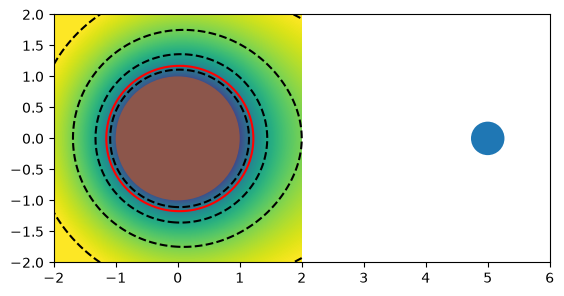

In [11]:
M_zem = 1
R_zem = 1

# v skutocnosti d_mesic = 60, M_mesic = 0.012
M_mesic = 0.5
d_mesic = 5

N = 1000
D = 2
XX, YY = np.meshgrid(np.linspace(-D, D, N), np.linspace(-D, D, N))

# gravitacni potencial Zeme
phi_zem = -M_zem / np.sqrt(XX**2 + YY**2)

# gravitacni potencial Mesice
phi_mesic = -M_mesic / np.sqrt((XX - d_mesic)**2 + YY**2)

# celkovy gravitacni potencial je soucet vsech
phi = phi_zem + phi_mesic

Zem = Circle((0,0), radius=1, fc="tab:brown")
Mesic = Circle((d_mesic, 0), radius=0.27, fc="tab:blue")

fig, ax = plt.subplots()
ax.set_aspect("equal")
ax.set_xlim(-2, 6)
ax.set_ylim(-2, 2)

ix = np.sqrt(XX**2 + YY**2) < 0.0
phi[ix] = 0
# print(ix.shape, XX[ix].shape)
ax.pcolormesh(XX, YY, phi, vmin=-1.3, vmax=-0.5)

ax.contour(XX, YY, phi, levels = np.linspace(-1, -0.5, 4), colors="k")

# ekvipotenciala phi = -0.95
contours = measure.find_contours(phi, -0.95)
cx, cy = contours[0][:, 1]/N*2*D - D, contours[0][:, 0]/N*2*D - D

ax.plot(cx, cy, color="red")

ax.add_patch(Zem)
ax.add_patch(Mesic)


Výška ekvipotenciály $\phi = -0.95$ na $R=1$.

Mierna asymetria okolo $\pm\pi$ je numerická chyba

Text(0, 0.5, '$R_\\phi - R_Z$')

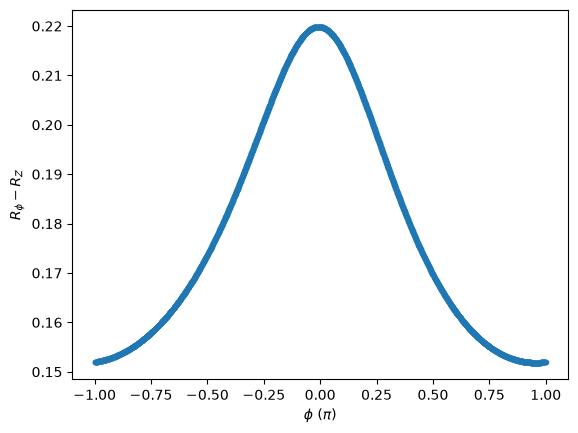

In [3]:
cR = np.sqrt(cx**2 + cy**2)
ctheta = np.atan2(cy, cx)

fig, ax = plt.subplots()
ax.plot(ctheta/np.pi, cR - 1, 'o', ms=3)
ax.set_xlabel("$\\phi$ ($\\pi$)")
ax.set_ylabel(r"$R_\phi - R_Z$")

Toto by naznačovalo, že za 1 deň (jedno otočenie zeme okolo svojej osy) by mal nastať jeden príliv a jeden odliv. To ale nie je pravda -- prílivy a odlivy nastávajaú každých 12 hodín -- maximálny príliv je kolmo pod mesiacom a tiež (trocha slabší) na opačnej strane Zeme.

Musíme započítať aj odstredivú silu kvôli rotácií systému Zem - Mesiac okolo spoločného ťažiska.

Text(0.5, 1.0, 'Celkové zrychlení (gravitace + odstředivé) kolmé na polohový vektor.')

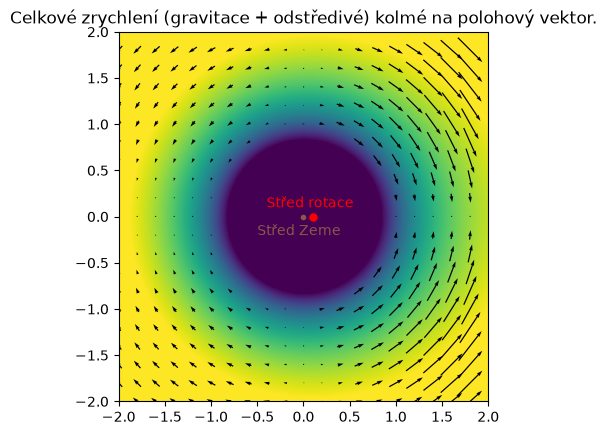

In [20]:
Fx, Fy = np.gradient(-phi, 2*D/N, 2*D/N, axis=(1, 0))
F0x, F0y = np.gradient(-phi_zem, 2*D/N, 2*D/N, axis=(1, 0))

fig, ax = plt.subplots()
ax.set_aspect("equal")
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)

ax.pcolormesh(XX, YY, phi, vmin=-1.3, vmax=-0.6)

### odstredive sily
# stred otaceni
x0 = 0.1
y0 = 0
Rod = np.sqrt((XX - x0)**2 + (YY - y0)**2)
omega = 2*np.pi/(15) # zvolene tak, aby to slo vidiet na obrazku

# pricteme odstredivou silu ke gravitacni
Fx += omega**2*(XX - x0)
Fy += omega**2*(YY - y0)

# projektujeme silu do smeru kolmeho na polohovy vektor
# t.j. sila tecna k povrchu zeme
RR = np.sqrt(XX**2 + YY**2)
FdotR = Fx*XX + Fy*YY
Ftx = Fx - FdotR/RR**2 * XX
Fty = Fy - FdotR/RR**2 * YY

K = 50
ix = (XX[::K, ::K]**2 + YY[::K, ::K]**2) > 1
ax.quiver(XX[::K, ::K][ix], YY[::K, ::K][ix], Ftx[::K, ::K][ix], Fty[::K, ::K][ix], pivot="middle", scale=0.25)

ax.plot([x0], [y0], 'o', ms=5, color="red")
ax.text(x0-0.5, y0+0.1, "Střed rotace", color="red")

ax.plot([0], [0], 'o', ms=3, color="tab:brown")
ax.text(-0.5, -0.2, "Střed Zeme", color="tab:brown")

ax.set_title("Celkové zrychlení (gravitace + odstředivé) kolmé na polohový vektor.")